In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
from skimage.metrics import peak_signal_noise_ratio

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")

ModuleNotFoundError: No module named 'skimage'

In [2]:
%pip install scikit-image

   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.9 MB 640.0 kB/s eta 0:00:19
   ---------------------------------------- 0.1/11.9 MB 744.7 kB/s eta 0:00:16
    --------------------------------------- 0.2/11.9 MB 1.0 MB/s eta 0:00:12
    --------------------------------------- 0.3/11.9 MB 1.1 MB/s eta 0:00:11
    --------------------------------------- 0.3/11.9 MB 1.2 MB/s eta 0:00:10
   - -------------------------------------- 0.4/11.9 MB 1.3 MB/s eta 0:00:09
   - -------------------------------------- 0.5/11.9 MB 1.5 MB/s eta 0:00:08
   --- ------------------------------------ 0.9/11.9 MB 2.1 MB/s eta 0:00:06
   --- ------------------------------------ 1.1/11.9 MB 2.5 MB/s eta 0:00:05
   ----- ---------------------------------- 1.6/11.9 MB 3.2 MB/s eta 0:00:04
   ------ --------------------------------- 2.0/11.9 MB 3.8 MB/s eta 0:00:03
   --------- ------------------------------ 2.7/11.9 MB 4.7 MB/s eta 0:00:02
  

ERROR: Exception:
Traceback (most recent call last):
  File "c:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\pip\_vendor\urllib3\response.py", line 438, in _error_catcher
    yield
  File "c:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\pip\_vendor\urllib3\response.py", line 561, in read
    data = self._fp_read(amt) if not fp_closed else b""
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\pip\_vendor\urllib3\response.py", line 527, in _fp_read
    return self._fp.read(amt) if amt is not None else self._fp.read()
           ^^^^^^^^^^^^^^^^^^
  File "c:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\pip\_vendor\cachecontrol\filewrapper.py", line 98, in read
    data: bytes = self.__fp.read(amt)
                  ^^^^^^^^^^^^^^^^^^^
  File "c:\Users\user\AppData\Local\Programs\Python\Python312\Lib\http\client.py", line 479, in read
    s = self.fp.read(amt)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
from skimage.metrics import peak_signal_noise_ratio

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")

ModuleNotFoundError: No module named 'skimage'

In [2]:
%pip install scikit-image

  Using cached scikit_image-0.26.0-cp312-cp312-win_amd64.whl.metadata (15 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached imageio-2.38.1-py3-none-any.whl.metadata (9.7 kB)
  Using cached tifffile-2026.10.15-py3-none-any.whl.metadata (34 kB)
  Using cached lazy_loader-0.6-py3-none-any.whl.metadata (6.0 kB)
   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.9 MB 1.9 MB/s eta 0:00:07
   ---------------------------------------- 0.1/11.9 MB 653.6 kB/s eta 0:00:19
   ---------------------------------------- 0.1/11.9 MB 1.0 MB/s eta 0:00:12
    --------------------------------------- 0.2/11.9 MB 1.1 MB/s eta 0:00:11
   - -------------------------------------- 0.3/11.9 MB 1.1 MB/s eta 0:00:11
   -- ------------------------------------- 0.6/11.9 MB 1.6 MB/s eta 0:00:08
   -- ------------------------------------- 0.6/11.9 MB 1.6 MB/s eta 0:00:08
   --- ------------------------------------ 1.1/


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import sys
print(sys.executable)

%pip show scikit-image

c:\Users\user\AppData\Local\Programs\Python\Python312\python.exe
Name: scikit-image
Version: 0.26.0
Summary: Image processing in Python
Home-page: 
Author: 
Author-email: 
License: Files: *
 Copyright: 2009-2022 the scikit-image team
 License: BSD-3-Clause

 Files: doc/source/themes/scikit-image/layout.html
 Copyright: 2007-2010 the Sphinx team
 License: BSD-3-Clause

 Files: skimage/feature/_canny.py
        skimage/filters/edges.py
        skimage/filters/_rank_order.py
        skimage/morphology/_skeletonize.py
        skimage/morphology/tests/test_watershed.py
        skimage/morphology/watershed.py
        skimage/segmentation/heap_general.pxi
        skimage/segmentation/heap_watershed.pxi
        skimage/segmentation/_watershed.py
        skimage/segmentation/_watershed_cy.pyx
 Copyright: 2003-2009 Massachusetts Institute of Technology
            2009-2011 Broad Institute
            2003 Lee Kamentsky
            2003-2005 Peter J. Verveer
 License: BSD-3-Clause

 Files: skima

In [1]:
from skimage.metrics import peak_signal_noise_ratio

print("scikit-image is ready!")

scikit-image is ready!


In [2]:
import numpy as np

def calculate_psnr(reference, estimate):
    reference = np.asarray(reference, dtype=float)
    estimate = np.asarray(estimate, dtype=float)

    if reference.shape != estimate.shape:
        raise ValueError(
            "Reference and estimate must have the same shape."
        )

    data_range = np.max(reference) - np.min(reference)

    if data_range <= 0:
        raise ValueError(
            "Reference image must have a positive intensity range."
        )

    mse = np.mean((reference - estimate) ** 2)

    if mse == 0:
        return float("inf")

    return float(10 * np.log10((data_range ** 2) / mse))


# Test the function
reference_test = np.array([0.0, 0.5, 1.0, 0.75])
estimate_test = np.array([0.0, 0.4, 0.9, 0.8])

print(f"Test PSNR: {calculate_psnr(reference_test, estimate_test):.2f} dB")

Test PSNR: 22.50 dB


{
    "reference": "Full-array DAS image",
    "inactive_sensor_count": 8,
    "inactive_sensor_percentage": 25.0,
    "inactive_sensor_indices": [
        2,
        12,
        17,
        20,
        22,
        25,
        28,
        30
    ],
    "psnr_incomplete_db": 23.37970883805026,
    "psnr_linear_db": 59.02654085962795,
    "psnr_spline_db": 75.2096545652984
}


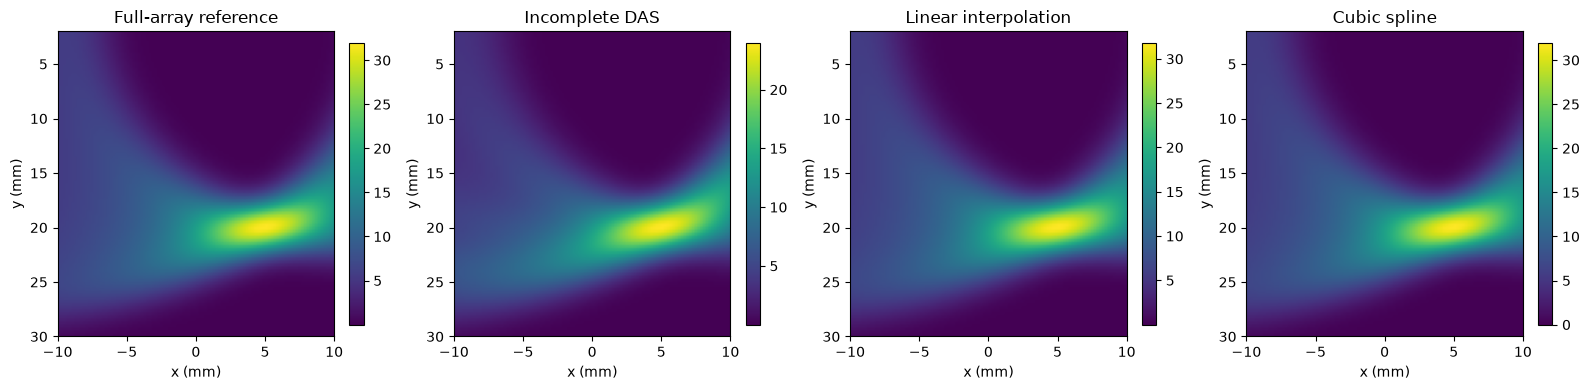

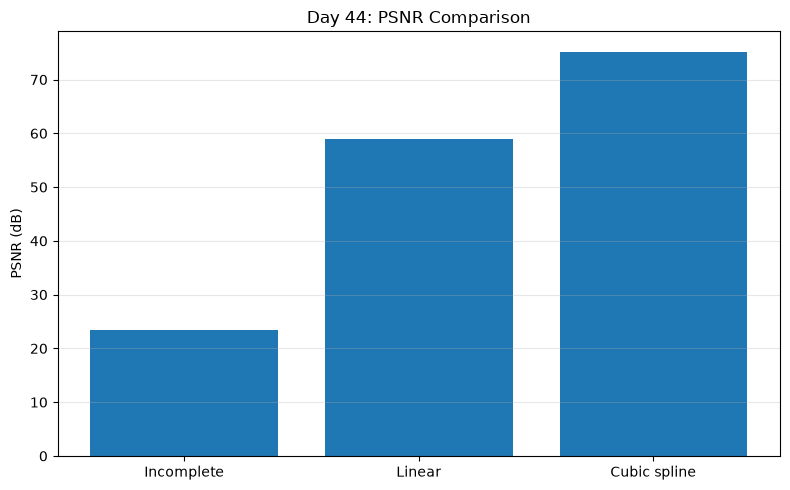

Saved PSNR results and figures to outputs.


In [3]:

import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
from scipy.interpolate import interp1d, CubicSpline

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Simulation parameters
c = 1500.0
fs = 10e6
n_sensors = 32
num_samples = 600
pulse_width = 1.5e-6

sensor_x = np.linspace(-15e-3, 15e-3, n_sensors)
time = np.arange(num_samples) / fs

source_x = 5e-3
source_y = 20e-3

x_grid = np.linspace(-10e-3, 10e-3, 100)
y_grid = np.linspace(2e-3, 30e-3, 100)
X, Y = np.meshgrid(x_grid, y_grid)

# Generate synthetic signals
signals = np.zeros((n_sensors, num_samples))

for i in range(n_sensors):
    distance = np.sqrt(
        (source_x - sensor_x[i])**2 + source_y**2
    )
    arrival_time = distance / c
    signals[i] = np.exp(
        -((time - arrival_time) / pulse_width)**2
    )

# DAS reconstruction
def reconstruct_das(signal_matrix):
    image = np.zeros_like(X, dtype=float)

    for i in range(n_sensors):
        distance_map = np.sqrt(
            (X - sensor_x[i])**2 + Y**2
        )
        travel_time = distance_map / c

        sampled = np.interp(
            travel_time.ravel(),
            time,
            signal_matrix[i],
            left=0,
            right=0
        )

        image += sampled.reshape(X.shape)

    return image

# PSNR calculation
def calculate_psnr(reference, estimate):
    reference = np.asarray(reference, dtype=float)
    estimate = np.asarray(estimate, dtype=float)

    if reference.shape != estimate.shape:
        raise ValueError("Images must have the same shape.")

    data_range = np.max(reference) - np.min(reference)

    if data_range <= 0:
        raise ValueError("Reference image has zero intensity range.")

    mse = np.mean((reference - estimate)**2)

    if mse == 0:
        return float("inf")

    return float(10 * np.log10(data_range**2 / mse))

# Full-array reference image
reference_image = reconstruct_das(signals)

# Eight inactive sensors (25%)
rng = np.random.default_rng(42)
inactive_indices = np.sort(rng.choice(
    n_sensors, size=8, replace=False
))
active_indices = np.setdiff1d(
    np.arange(n_sensors), inactive_indices
)

damaged_signals = signals.copy()
damaged_signals[inactive_indices] = 0

# Reconstruct without interpolation
incomplete_image = reconstruct_das(damaged_signals)

# Linear interpolation
linear_interp = interp1d(
    active_indices,
    damaged_signals[active_indices],
    axis=0,
    kind="linear",
    bounds_error=False,
    fill_value="extrapolate"
)

linear_signals = damaged_signals.copy()
linear_signals[inactive_indices] = linear_interp(inactive_indices)
linear_image = reconstruct_das(linear_signals)

# Cubic spline interpolation
spline_interp = CubicSpline(
    active_indices,
    damaged_signals[active_indices],
    axis=0,
    bc_type="natural",
    extrapolate=True
)

spline_signals = damaged_signals.copy()
spline_signals[inactive_indices] = spline_interp(inactive_indices)
spline_image = reconstruct_das(spline_signals)

# Evaluate PSNR
results = {
    "reference": "Full-array DAS image",
    "inactive_sensor_count": 8,
    "inactive_sensor_percentage": 25.0,
    "inactive_sensor_indices": inactive_indices.tolist(),
    "psnr_incomplete_db": calculate_psnr(
        reference_image, incomplete_image
    ),
    "psnr_linear_db": calculate_psnr(
        reference_image, linear_image
    ),
    "psnr_spline_db": calculate_psnr(
        reference_image, spline_image
    )
}

print(json.dumps(results, indent=4))

# Plot image comparison
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

images = [
    reference_image,
    incomplete_image,
    linear_image,
    spline_image
]

titles = [
    "Full-array reference",
    "Incomplete DAS",
    "Linear interpolation",
    "Cubic spline"
]

for ax, image, title in zip(axes, images, titles):
    im = ax.imshow(
        image,
        extent=[
            x_grid[0] * 1e3, x_grid[-1] * 1e3,
            y_grid[-1] * 1e3, y_grid[0] * 1e3
        ],
        aspect="auto"
    )
    ax.set_title(title)
    ax.set_xlabel("x (mm)")
    ax.set_ylabel("y (mm)")
    fig.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.savefig(
    "../outputs/day44_psnr_image_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Plot PSNR comparison
labels = ["Incomplete", "Linear", "Cubic spline"]
values = [
    results["psnr_incomplete_db"],
    results["psnr_linear_db"],
    results["psnr_spline_db"]
]

plt.figure(figsize=(8, 5))
plt.bar(labels, values)
plt.ylabel("PSNR (dB)")
plt.title("Day 44: PSNR Comparison")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    "../outputs/day44_psnr_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Save results
with open(
    output_dir / "day44_psnr_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

print("Saved PSNR results and figures to outputs.")
